<h2>Imports</h2>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h2>Read, clean and prepare data</h2>

In [ ]:
data = pd.read_csv("vacancies_warsaw.csv",
                 on_bad_lines='skip')
print(f"Vacancies: {len(data)}")
data.head(3)

Vacancies: 500


,title,company,work_format,employment_type,posted,applicants,seniority_level,agile,airflow,android,...,tdd,team_leadership,teamcity,terraform,typescript,ukrainian,unit_testing,unity,unreal,vue
0,Junior Software Engineer,Bolt,hybrid,full-time,23 часа назад,80 человек нажали «Подать заявку»,junior,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,Python Trainee,EPAM Systems,remote,internship,2 недели назад,Более 100 человек нажали «Подать заявку»,internship,False,False,False,...,False,True,False,False,False,False,False,False,False,False
2,Graduate software engineer (Warsaw),WeTransfer,hybrid,NaN,1 день назад,16 человек нажали «Подать заявку»,entry,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
#bool - Is there a skill in job description?
print(data.dtypes.value_counts())

bool      96
object     7
Name: count, dtype: int64


In [ ]:
def calculate_missings():
  missing = data.isnull().sum()
  missing_pct = (missing / len(data)) * 100
  missing_df = pd.DataFrame({
      'Missing values': missing,
      '%': missing_pct
  }).sort_values('%', ascending=False)
  print(missing_df[missing_df['Missing values'] > 0])
calculate_missings()

                 Missing values     %
seniority_level             280  56.0
employment_type             148  29.6
work_format                 130  26.0
posted                       68  13.6
applicants                   39   7.8


In [ ]:
import re

def get_applicants(text):
  if pd.isna(text):
    return 0
  applicants = str(text).lower()
  match = re.search(r'(\d+)', text)
  if match:
    return int(match.group(0))
  return 0

def get_posted(text):
  if pd.isna(text):
    return None
  text = str(text).lower()
  match = re.search(r'(\d+)\s+([а-я]+)', text)
  if not match:
    return None
  amount = int(match.group(1))
  unit = match.group(2)

  if "час" in unit or "мин" in unit or "hour" in unit or "min" in unit:
    return 0
  if "год" in unit or "year" in unit:
    return 365 * amount
  if "месяц" in unit or "month" in unit:
    return 30 * amount
  if "недел" in unit or "week" in unit:
    return 7 * amount
  return amount

data["applicants_count"]=data["applicants"].apply(get_applicants)
data["days_ago"]=data["posted"].apply(get_posted)

data[['title', 'company', 'posted', 'days_ago', 'applicants', 'applicants_count']].head(5)


,title,company,posted,days_ago,applicants,applicants_count
0,Junior Software Engineer,Bolt,23 часа назад,0.0,80 человек нажали «Подать заявку»,80
1,Python Trainee,EPAM Systems,2 недели назад,14.0,Более 100 человек нажали «Подать заявку»,100
2,Graduate software engineer (Warsaw),WeTransfer,1 день назад,1.0,16 человек нажали «Подать заявку»,16
3,Junior .NET Developer for Netcompany Banking S...,Netcompany,3 дня назад,3.0,39 кандидатов,39
4,Software Engineer,Aurora Energy Research,NaN,NaN,33 человека нажали «Подать заявку»,33


In [ ]:
import re

def has(pattern, text):
    """Whole-word regex match, so 'ai' does not match 'trainee'."""
    return re.search(r'(?<![a-z0-9])(?:' + pattern + r')(?![a-z0-9])', text) is not None

def categorize_job(title):
    title = str(title).lower()



    if has(r'cyber|security|information security|infosec|application security|appsec|network security|cloud security|security engineer|security analyst|security architect|security researcher|vulnerability|penetration|pentest|ethical hacking|red team|blue team|soc analyst|security operations|incident response|threat intelligence|malware|reverse engineering|cryptography|identity access management|iam|compliance|risk management|iso 27001|nist|grc|security audit|security consultant', title):
      return 'Cybersecurity'

    # 1. AI / Machine Learning
    if has(r'ai|ml|machine learning|artificial intelligence|intelligence|gen ai|conversational', title):
        return 'AI / Machine Learning'

    # 2. Data Engineering / Science / Analysis
    if has(r'data|big data|analytics|database|sql|warehouse|powerbi|snowflake|bi', title):
        return 'Data & Analytics'

    # 3. Backend (Python)
    if has(r'python|django|flask|dash|streamlit|fastapi', title):
        return 'Python Developer'

    # 4. Backend (Other: .NET, Java, C++, Go, PHP)
    if has(r'\.net|c#|java|c\+\+|cpp|golang|node|backend|back-end|php|ruby|erlang|assembler', title):
        return 'Backend Developer (Other)'

    # 5. Frontend / Mobile / UI
    if has(r'frontend|front-end|react|angular|vue|javascript|typescript|ts|ui|mobile|android|ios|flutter|rendering|graphics', title):
        return 'Frontend / UI / Mobile'

    # 6. Embedded / Robotics / Systems
    if has(r'embedded|robotics|firmware|hardware|soc|system software|iot|gnc|low latency', title):
        return 'Embedded & Systems'

    # 7. QA / Testing / Automation
    if has(r'qa|test|testing|validation|tester|manualny|automated', title):
        return 'QA / SDET'

    # 8. DevOps / Cloud / Infrastructure
    if has(r'devops|cloud|azure|aws|gcp|chmurowy|infrastructure|networking', title):
        return 'Cloud & DevOps'

    # 9. Общие названия (Software Engineer без уточнения)
    if has(r'software engineer|software developer|programista|programistka|inżynier|developer', title):
        return 'General Software Engineer'

    # 10. Internships
    if has(r'intern|trainee|staz|staż|student|graduate|early career|talent program', title):
        return 'Internship / Graduate'

    return 'Other / Specialized'

data['job_group'] = data['title'].apply(categorize_job)


In [ ]:
data.loc[data["seniority_level"].isna(), "seniority_level"] = "Not specified"
data["employment_type"]=data["employment_type"].fillna("Not specified")
data["work_format"]=data["work_format"].fillna("Not specified")
data["days_ago"]=data["days_ago"].fillna(data["days_ago"].median())
calculate_missings()

            Missing values     %
posted                  68  13.6
applicants              39   7.8


In [ ]:
df = data.drop(columns=['applicants', 'posted'])
df.head(3)

,title,company,work_format,employment_type,seniority_level,agile,airflow,android,angular,ansible,...,terraform,typescript,ukrainian,unit_testing,unity,unreal,vue,applicants_count,days_ago,job_group
0,Junior Software Engineer,Bolt,hybrid,full-time,junior,False,False,False,False,False,...,False,True,False,False,False,False,False,80,0.0,General Software Engineer
1,Python Trainee,EPAM Systems,remote,internship,internship,False,False,False,False,False,...,False,False,False,False,False,False,False,100,14.0,AI / Machine Learning
2,Graduate software engineer (Warsaw),WeTransfer,hybrid,Not specified,entry,False,False,False,False,False,...,False,False,False,False,False,False,False,16,1.0,General Software Engineer


<h2>Basic stats</h2>

In [ ]:
print("=== BASIC STATS ===")
print(f"Total: {len(df)}")
print(f"\nSeniority distribution:")
print(df['seniority_level'].value_counts())
print(f"\nWork format:")
print(df['work_format'].value_counts())
print(f"\nTop 10 skills:")
# print(skill_counts.sort_values(ascending=False).head(10))


=== BASIC STATS ===
Total: 500

Seniority distribution:
seniority_level
Not specified    280
junior            62
senior            53
mid               48
internship        25
entry             13
lead              12
director           6
staff              1
Name: count, dtype: int64

Work format:
work_format
hybrid           202
Not specified    130
on-site          100
remote            68
Name: count, dtype: int64

Top 10 skills:


<h2>Distribution of skills & PLs</h2>

In [ ]:
# df_skills = df.drop(columns = ['title', 'company', 'work_format', 'employment_type','seniority_level', 'applicants_count', 'days_ago'])
df_skills = df.select_dtypes(include=['bool'])
display(df_skills.head(3))
df_skills.shape

,agile,airflow,android,angular,ansible,aws,azure,bdd,bigquery,blockchain,...,tdd,team_leadership,teamcity,terraform,typescript,ukrainian,unit_testing,unity,unreal,vue
0,False,False,False,False,False,True,True,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


(500, 96)

In [ ]:
skill_counts = df_skills.sum()
top_skills = skill_counts[skill_counts>100].sort_values(ascending=False)

In [ ]:
PLs = ['python', 'java', 'javascript', 'typescript', 'csharp', 'cpp', 'go', 'rust', 'ruby', 'php', 'swift', 'kotlin', 'r', 'scala', 'perl', 'lua']
PLs_counts = skill_counts[PLs].sort_values(ascending=False)
PLs_counts.head(3)

,0
python,239
java,184
scala,178


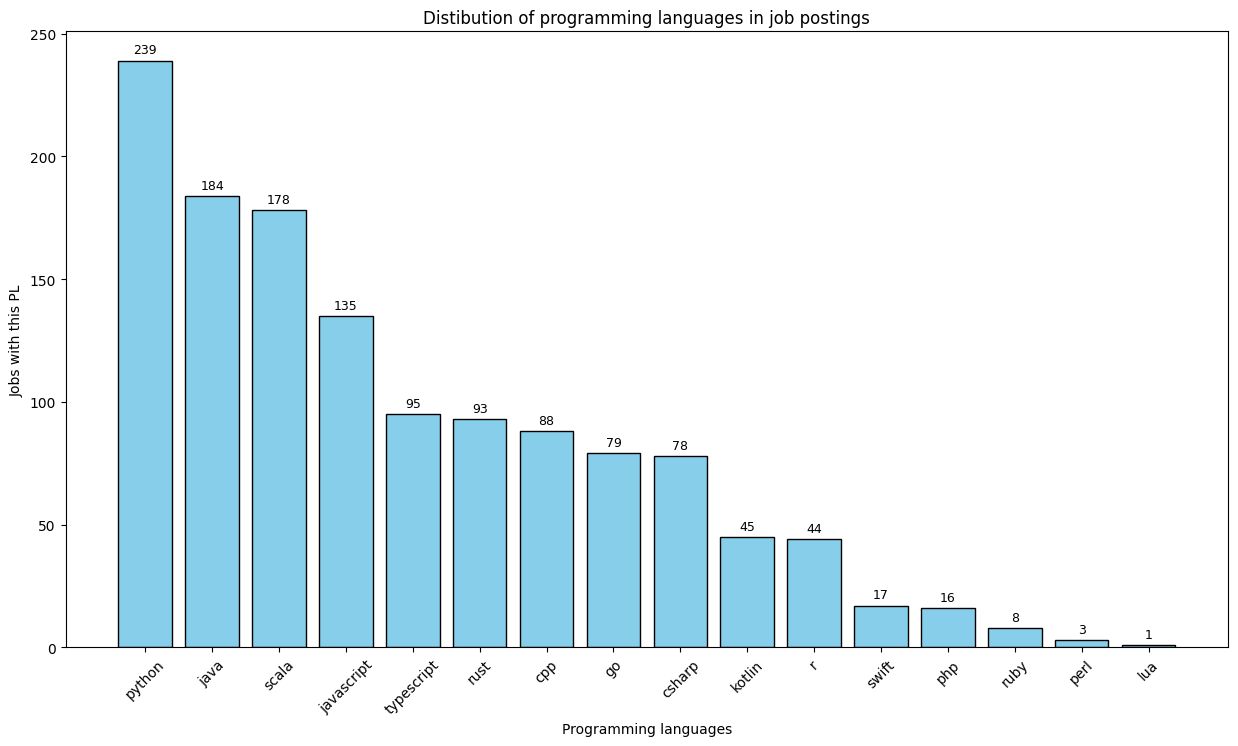

In [ ]:
plt.figure(figsize=(15, 8))
pl_bar = plt.bar(PLs_counts.index, PLs_counts.values, color = "skyblue", edgecolor= "black")
plt.bar_label(pl_bar, padding=3, fontsize=9)
plt.title("Distribution of programming languages in job postings")
plt.xticks(rotation=45)
plt.xlabel("Programming languages")
plt.ylabel("Jobs with this PL")
plt.show()

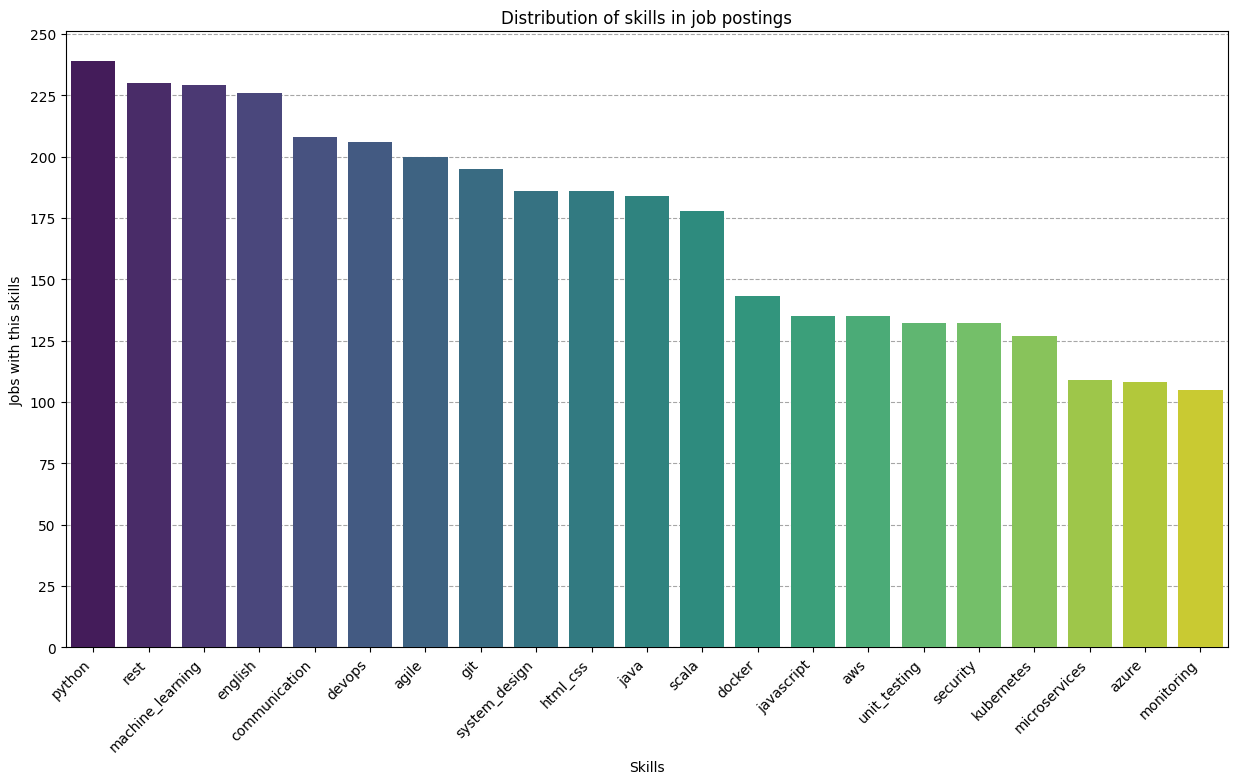

In [ ]:
plt.figure(figsize=(15, 8))
sns.barplot(x=top_skills.index, y=top_skills.values, hue=top_skills.index, legend=False, palette="viridis", zorder=3)
plt.xticks(rotation=45, ha='right')

max_value=top_skills.values.max()
step=25
ticks=np.arange(0, max_value+step, step)
plt.yticks(ticks)
plt.xlabel("Skills")
plt.ylabel("Jobs with this skills")
plt.title("Distribution of skills in job postings")
plt.grid(axis="y", color="gray", linestyle="--", alpha=0.7, zorder=0)

plt.show();

This plots illustrate the most frequently mentioned programming languages(skills) in job postings. It helps identify which programming languages(skills) are in high demand across various job roles, guiding job seekers on which languages to prioritize for their career growth.

<h2>Correlation matrix of programming languages</h2>
Heatmap for visualization





In [ ]:
skills_for_correlation = [
    'python', 'java', 'javascript', 'csharp', 'cpp',

    'html_css',

    'nodejs', 'rest', 'microservices',

    'postgresql', 'mysql', 'mongodb', 'redis',

    'aws', 'azure',

    'docker', 'kubernetes', 'git',

    'machine_learning', 'data_science',

    'english', 'polish'
]

print(f"All: {len(skills_for_correlation)}")

All: 22


In [ ]:
df_PLs = data[skills_for_correlation]
corr_matrix=df_PLs.corr()

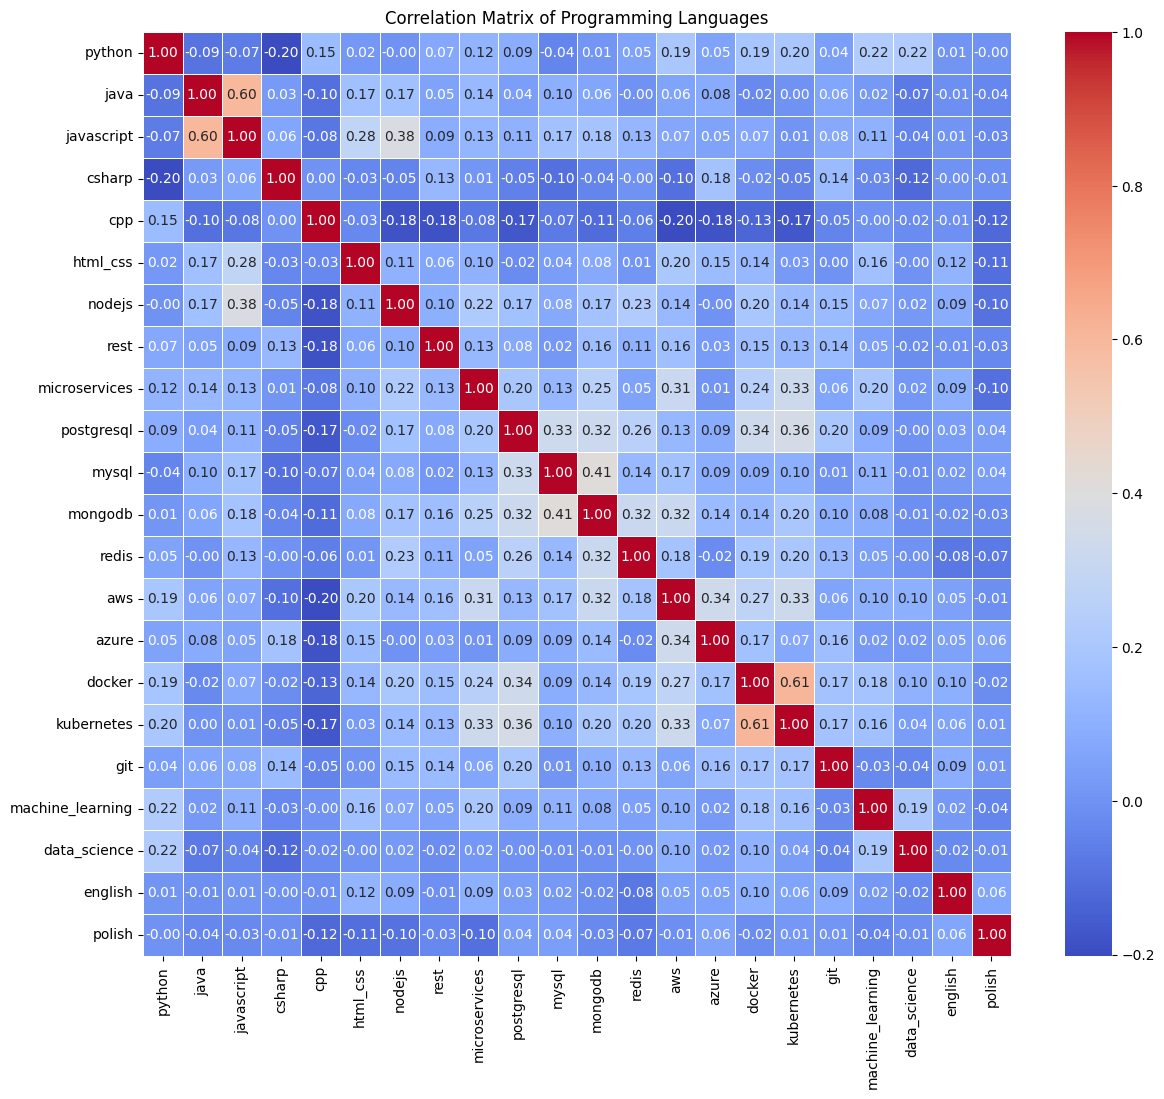

In [ ]:
plt.figure(figsize=(14, 12))
# mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Programming Languages")
plt.show()

This plot shows the relationships between various skills mentioned in job postings. It helps identify which skills often appear together, offering insights into the skill sets that are frequently required for different job roles.

<h2>Experience level distribution</h2>

In [ ]:
exp_level = data["seniority_level"].value_counts()
display(exp_level)

,count
seniority_level,
Not specified,280
junior,62
senior,53
mid,48
internship,25
entry,13
lead,12
director,6
staff,1


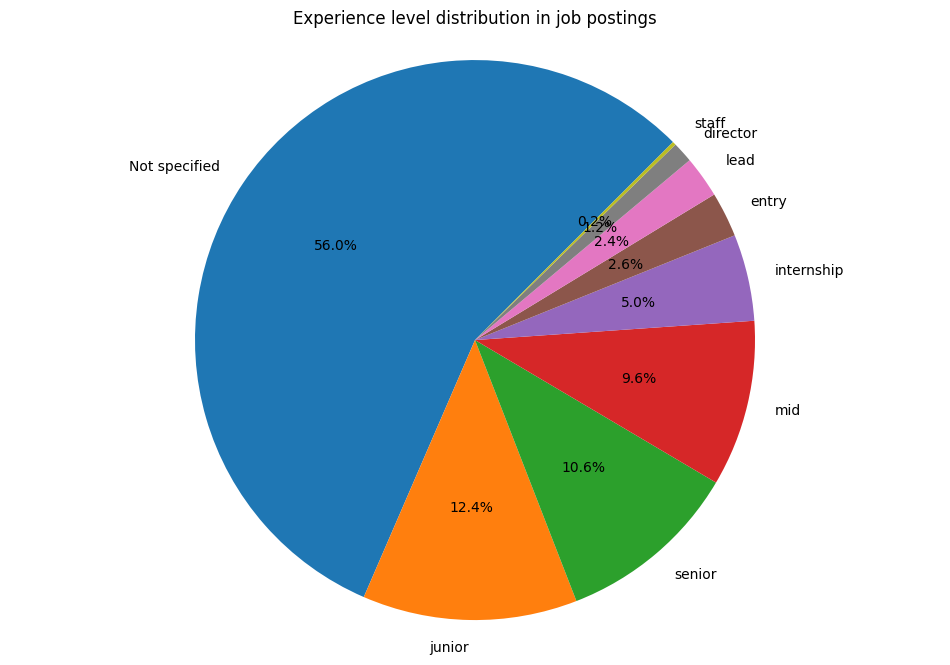

In [ ]:
plt.figure(figsize=(12,8))
pie = plt.pie(exp_level.values, labels = exp_level.index, autopct="%1.1f%%", startangle=45)
plt.title("Experience level distribution in job postings")
plt.axis('equal')
plt.show()

This chart shows the distribution of job postings based on the required experience levels, such as junior, mid-level, and senior positions. It reveals the general demand for professionals at different stages of their careers.

<h2>Work format distribution</h2>

In [ ]:
frmts = data["work_format"].value_counts()
display(frmts)

,count
work_format,
hybrid,202
Not specified,130
on-site,100
remote,68


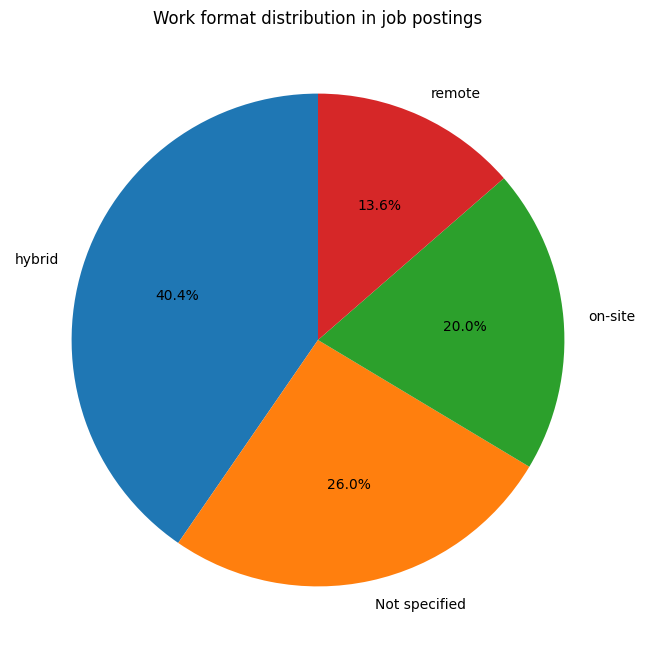

In [ ]:
plt.figure(figsize=(12,8))
pie = plt.pie(frmts.values, labels=frmts.index, autopct="%1.1f%%", startangle=90)
plt.title("Work format distribution in job postings")
plt.show()

This plot breaks down job postings into categories like on-site, remote, and hybrid positions. It provides insights into the work formats opportunities available and trends in job market preferences.

<h2>Employment type distribution</h2>

In [ ]:
tps = data["employment_type"].value_counts()
display(tps)

,count
employment_type,
full-time,328
Not specified,148
contract,11
internship,10
part-time,3


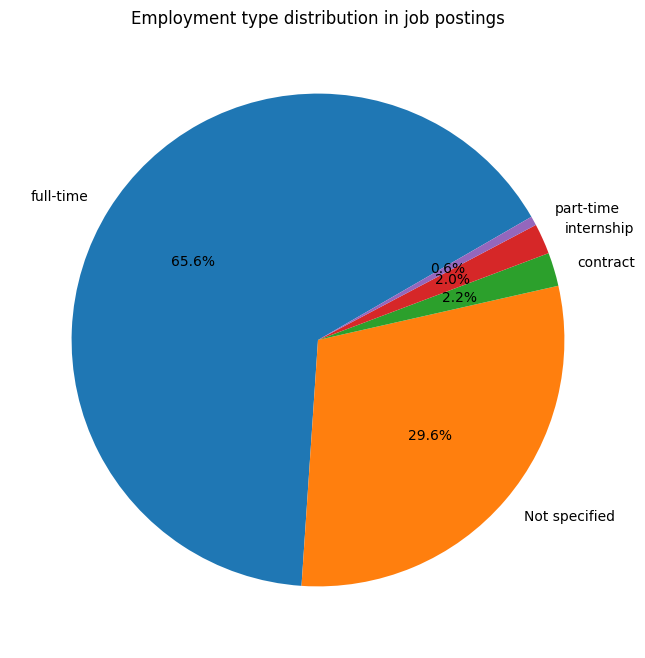

In [ ]:
plt.figure(figsize=(12,8))
pie = plt.pie(tps.values, labels=tps.index, autopct="%1.1f%%", startangle=30)
plt.title("Employment type distribution in job postings")
plt.show()

This plot breaks down job postings into categories like full-time, part-time, and contract positions. It provides insights into the types of employment opportunities available and trends in job market preferences.

<h2>Popular job titles</h2>

In [ ]:
titles = data["job_group"].value_counts()
titles=titles.sort_values(ascending=True)
titles.head(3)

,count
job_group,
Internship / Graduate,2
Cybersecurity,3
Embedded & Systems,11


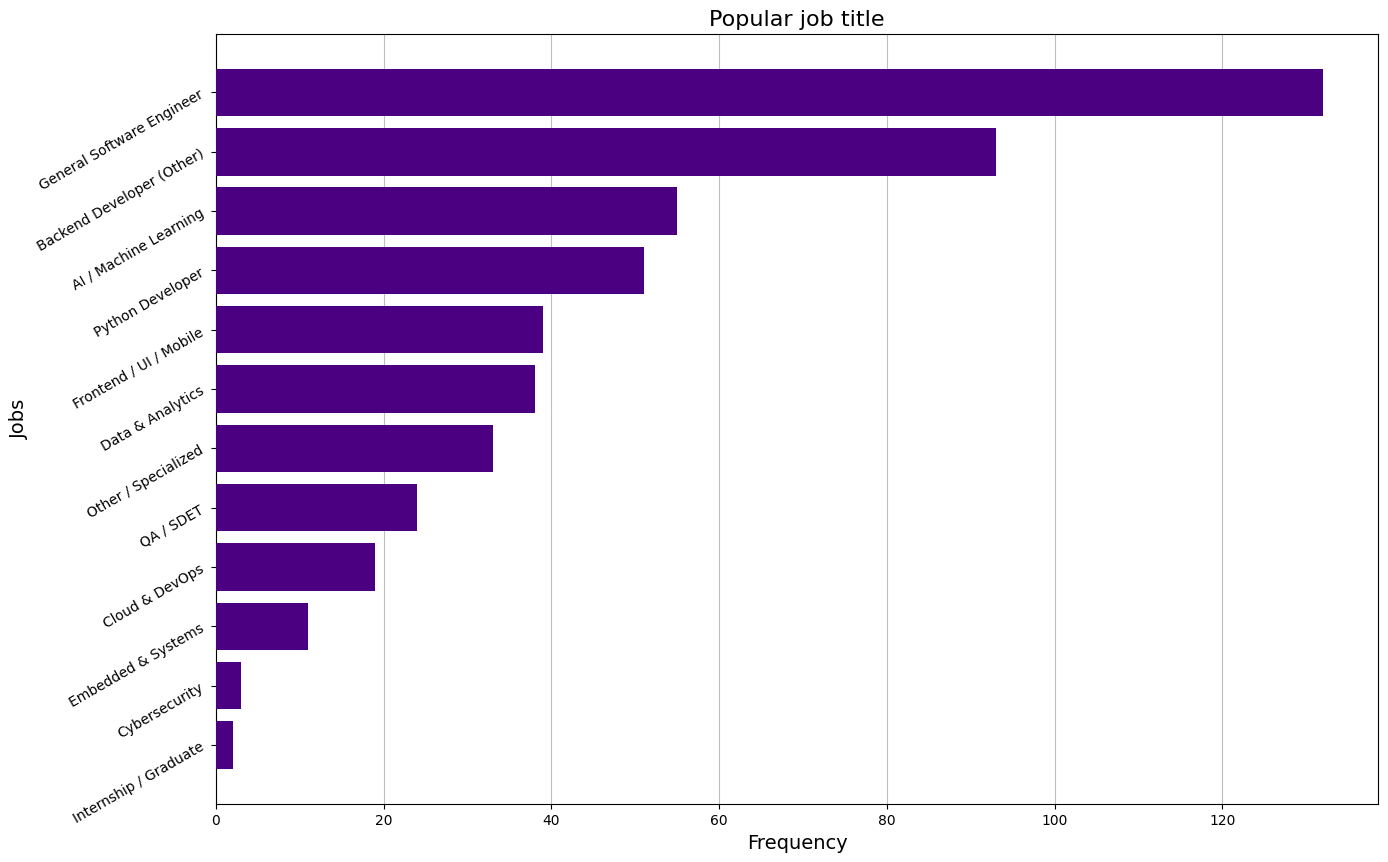

In [ ]:
plt.figure(figsize=(15, 10))
bars = plt.barh(titles.index, titles.values, color="indigo", zorder=3)
plt.grid(zorder=0, color="gray", alpha=0.5, axis='x')
plt.title("Popular job title", fontsize=16)
plt.ylabel('Jobs', fontsize=14)
plt.xlabel('Frequency', fontsize=14)
plt.yticks(rotation=30)
plt.show()

This visualization displays the ten most frequently listed job titles. It highlights which job roles are the most prevalent in the job market, helping job seekers identify popular positions.

<h2>Popular job employers</h2>

In [ ]:
companies = data["company"].value_counts()
companies=companies[companies.values>=5].sort_values(ascending=True)
companies.head(3)

,count
company,
Netflix,5
Integral Solutions - Data & AI,5
Aurora Energy Research,5


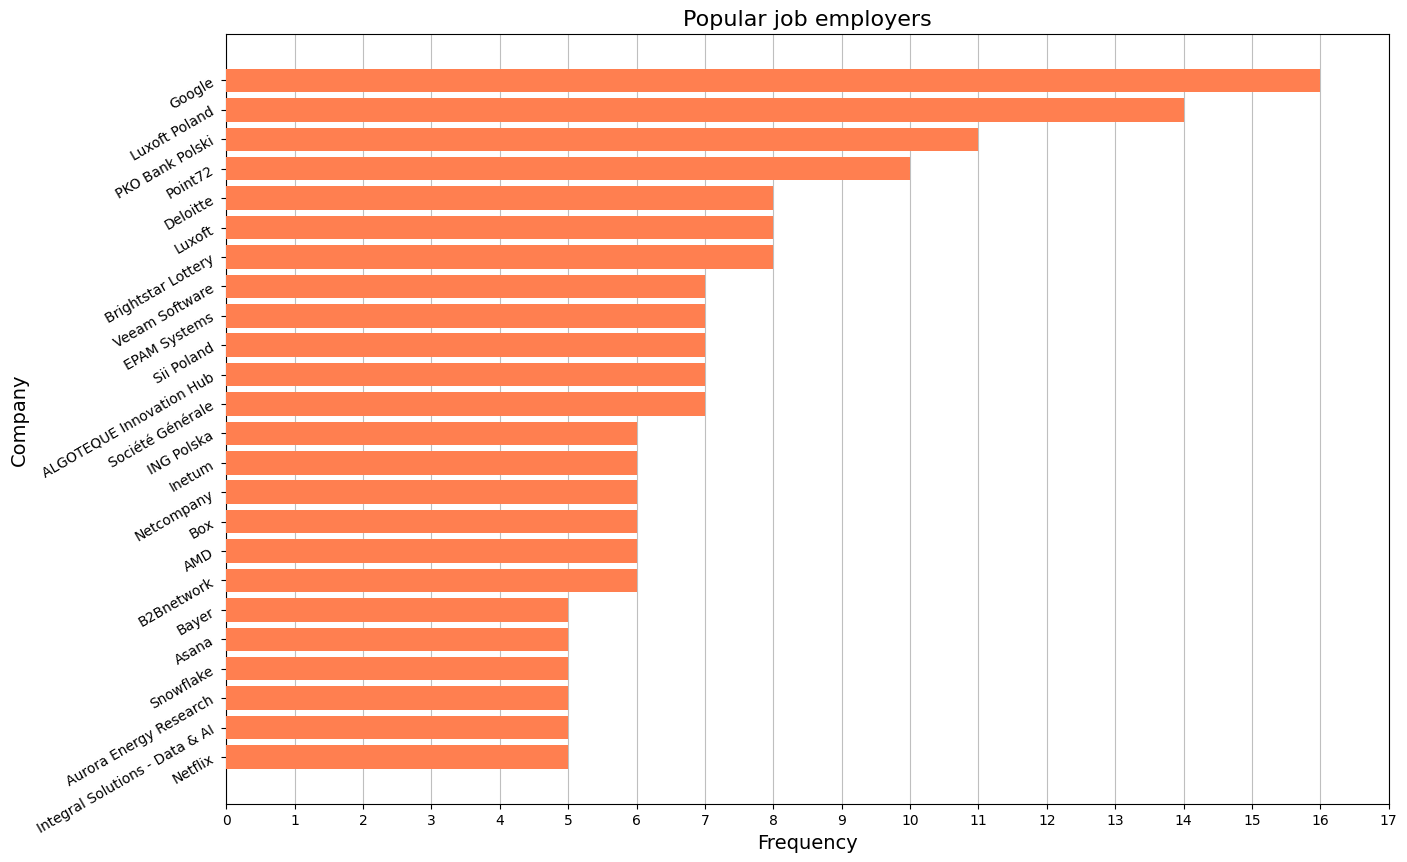

In [ ]:
plt.figure(figsize=(15, 10))
bars = plt.barh(companies.index, companies.values, color="coral", zorder=3)
plt.grid(zorder=0, color="gray", alpha=0.5, axis='x')
plt.title("Popular job employers", fontsize=16)
plt.ylabel('Company', fontsize=14)
plt.xlabel('Frequency', fontsize=14)
plt.xticks(np.arange(0, companies.values.max()+2, 1))
plt.yticks(rotation=30)
plt.show()

This visualization identifies the most active employers in the Warsaw job market, with EPAM, Google, and "PKO bank polski" leading in hiring volume.

<h2>Trend of job posting over time</h2>

In [ ]:
trend_data = data.groupby('days_ago').size()
trend_data.head(3)

,0
days_ago,
0.0,18
1.0,39
2.0,24


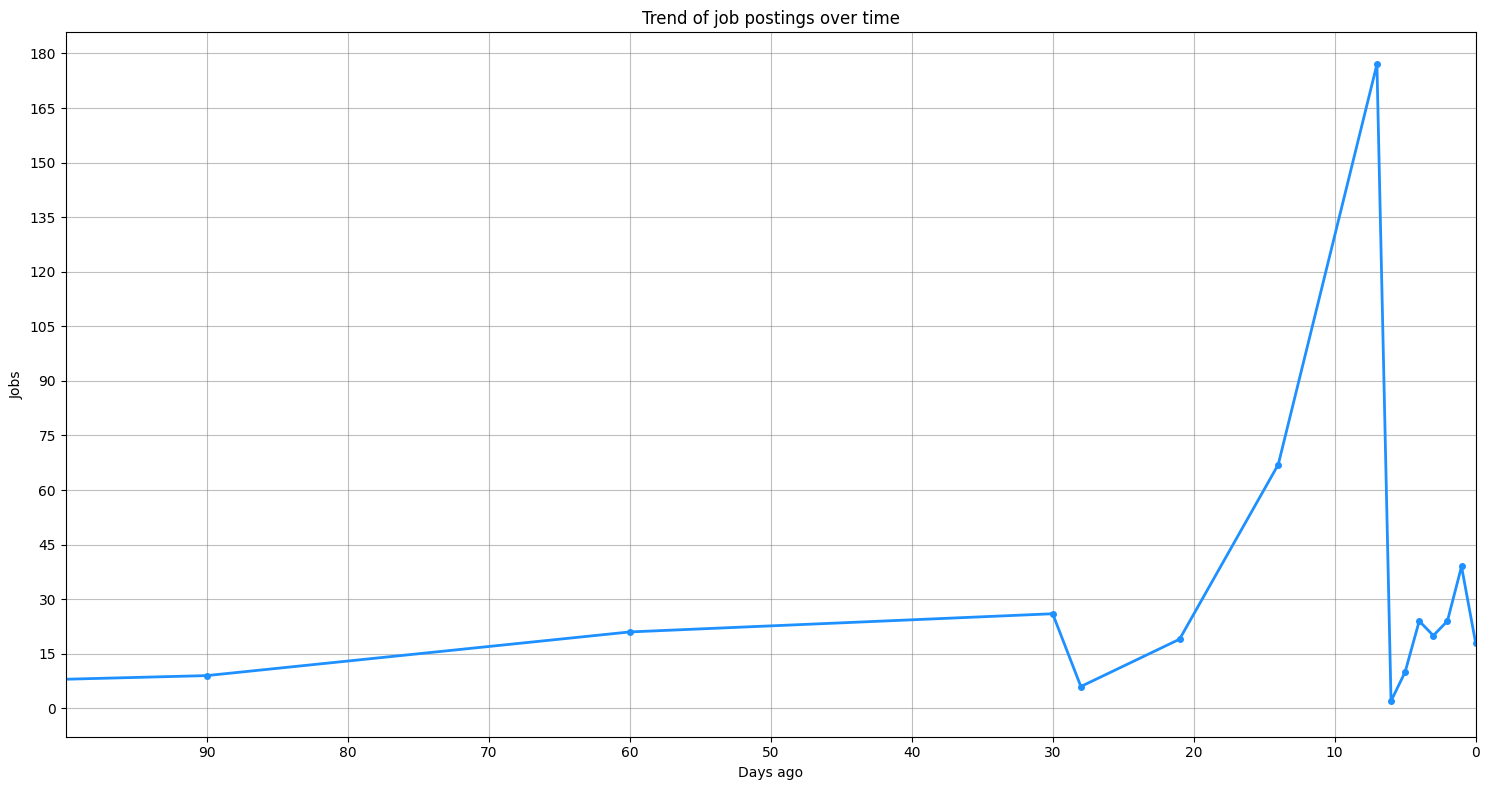

In [ ]:
fig, ax = plt.subplots(figsize=(15,8))

plotting=ax.plot(trend_data.index, trend_data.values, marker='o', markersize=4, linewidth=2, color='dodgerblue')
ax.set_title("Trend of job postings over time")
ax.set_xlabel("Days ago")
ax.set_ylabel("Jobs")
ax.invert_xaxis()
ax.set_xlim(100, 0)
plt.yticks(np.arange(0, trend_data.values.max()+5, 15))
plt.xticks(np.arange(0, 100, 10))
plt.grid(axis="both", color="gray", alpha=0.5)

plt.tight_layout()
plt.show()

This line chart tracks the number of job postings over time, giving a sense of the overall job market activity. It can reveal trends such as increased hiring periods or seasonal fluctuations in job postings.

<h2>Trend of Job Postings Over Time with Experience Level Distribution</h2>

In [ ]:
cols_req = ["days_ago", "seniority_level"]
counts = data.groupby(cols_req).size()

summary_table = counts.unstack(fill_value=0)
display(summary_table)

seniority_level,Not specified,director,entry,internship,junior,lead,mid,senior,staff
days_ago,,,,,,,,,
0.0,10,1,0,1,2,1,2,1,0
1.0,24,0,5,4,1,2,1,2,0
2.0,15,0,3,1,0,1,4,0,0
3.0,12,0,1,2,4,0,1,0,0
4.0,15,0,0,1,4,0,2,2,0
5.0,5,0,0,0,0,0,4,1,0
6.0,1,0,0,0,1,0,0,0,0
7.0,97,2,3,12,19,3,16,24,1
14.0,33,1,0,1,17,0,6,9,0


In [ ]:
unique_days=summary_table.index.unique()
unique_days_str = summary_table.index.astype(str).tolist()
unique_values=summary_table.columns.tolist()
unique_days.size

23

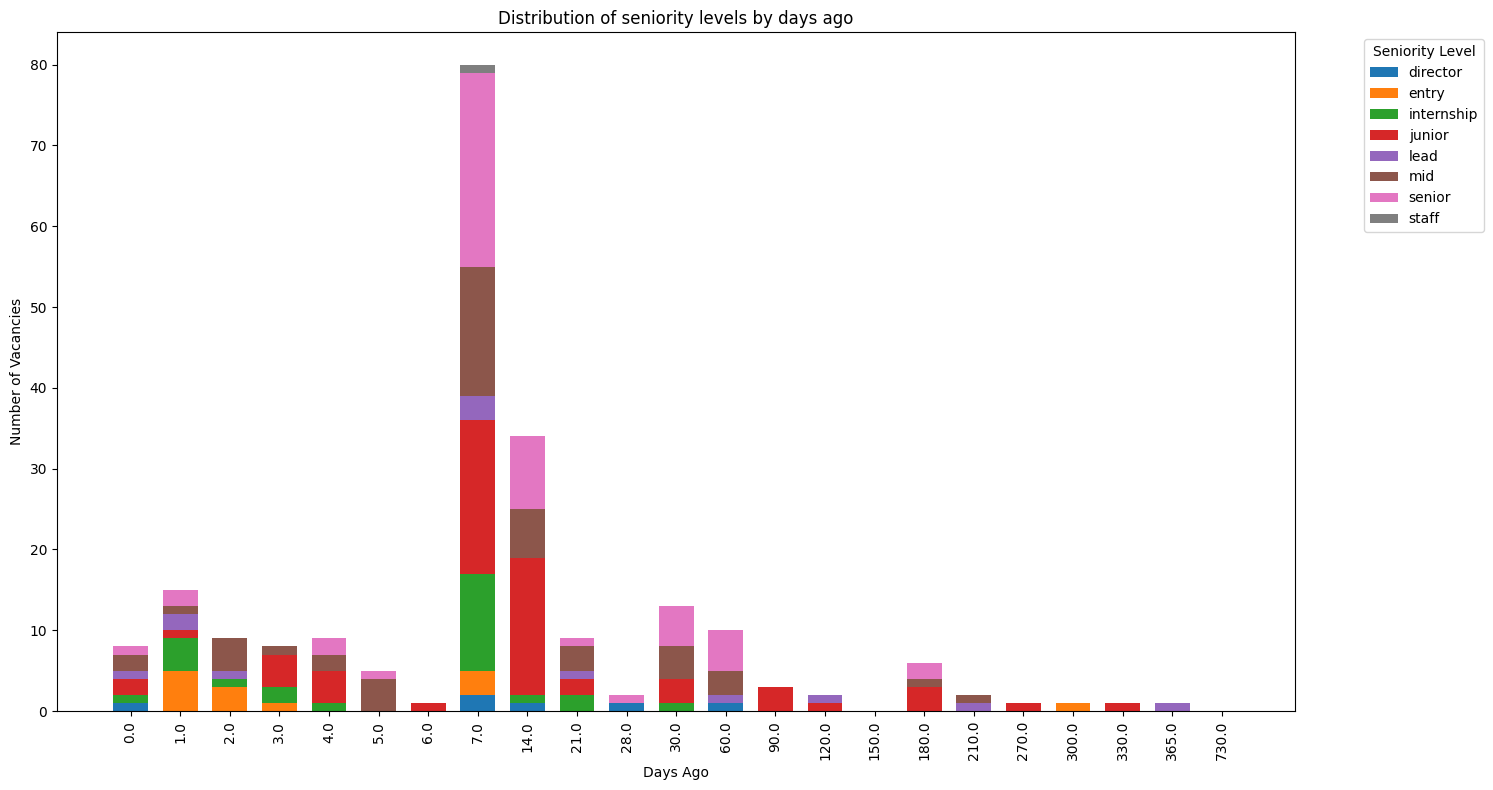

In [ ]:
fig, ax = plt.subplots(figsize=(15, 8))

bottom = np.zeros(unique_days.size)

for level in unique_values:
    if level == "Not specified":
        continue
    column_data = summary_table[level].values
    p = ax.bar(unique_days_str, column_data, 0.7, label=level, bottom=bottom)
    bottom += column_data

ax.set_title("Distribution of seniority levels by days ago")
ax.set_xlabel("Days Ago")
ax.set_ylabel("Number of Vacancies")

ax.legend(title="Seniority Level", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

This combined plot shows how job postings have varied over time, broken down by different experience levels. It highlights how demand for various experience levels has changed, offering insights into market trends for different career stages.

<h2>Number of Applicants per Job Title Group</h2>

In [ ]:
data["applicants_count"].mean()

np.float64(40.952)

/tmp/ipykernel_8076/2182611015.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bx=sns.boxplot(data, x='applicants_count', y='job_group', palette="Set3")


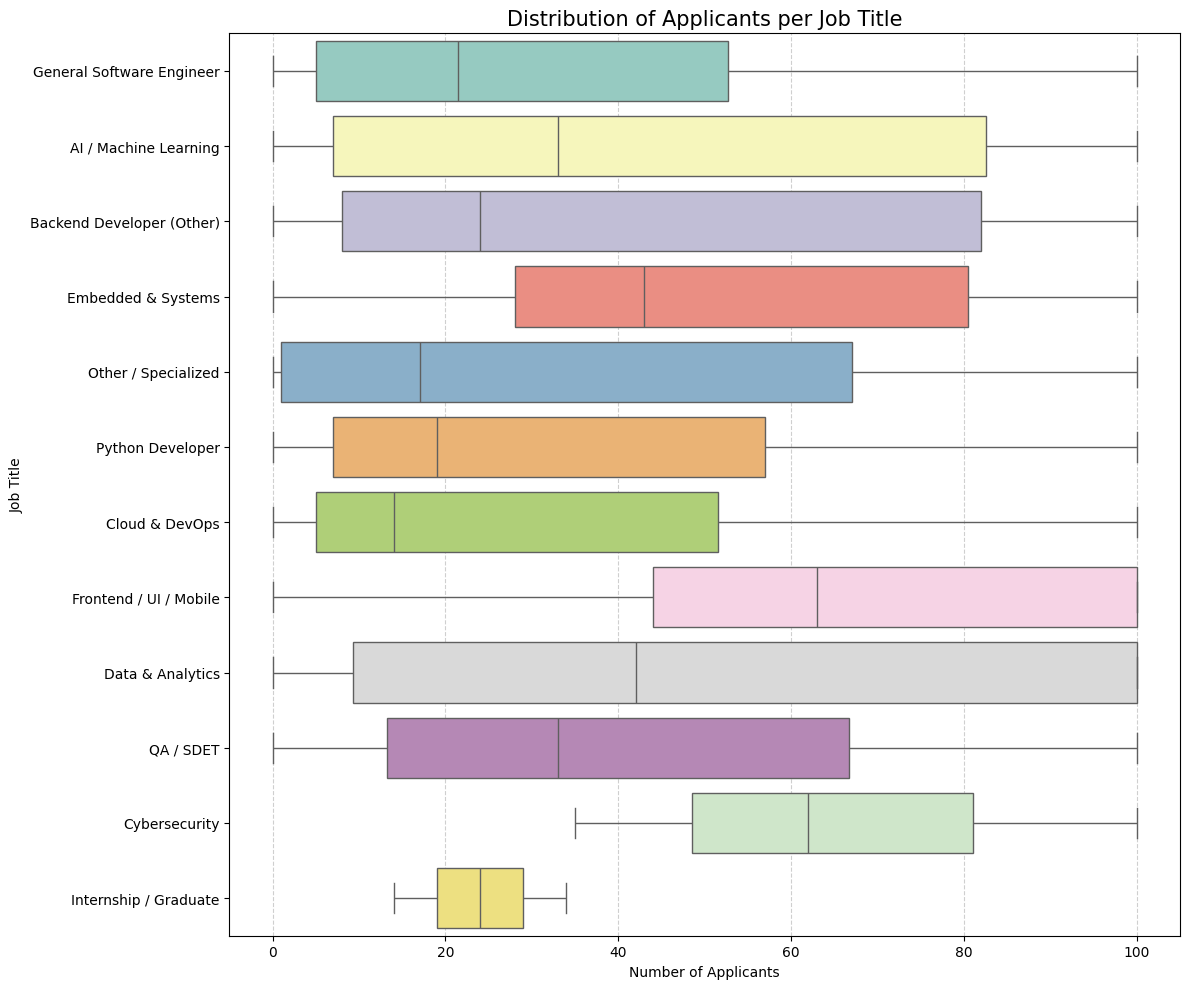

In [ ]:
plt.figure(figsize=(12, 10))

bx=sns.boxplot(data, x='applicants_count', y='job_group', palette="Set3")

plt.title("Distribution of Applicants per Job Title", fontsize=15)
plt.xlabel("Number of Applicants")
plt.ylabel("Job Title")
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

This plot visualizes the number of applicants for different job title groups. It indicates which job titles attract the most competition, helping job seekers understand where they might face more challenges. The mean for all job offers is 40.95 applicants.

<h2>Job Title Distribution</h2>

In [ ]:
title_dist = data["job_group"].value_counts()
# title_dist

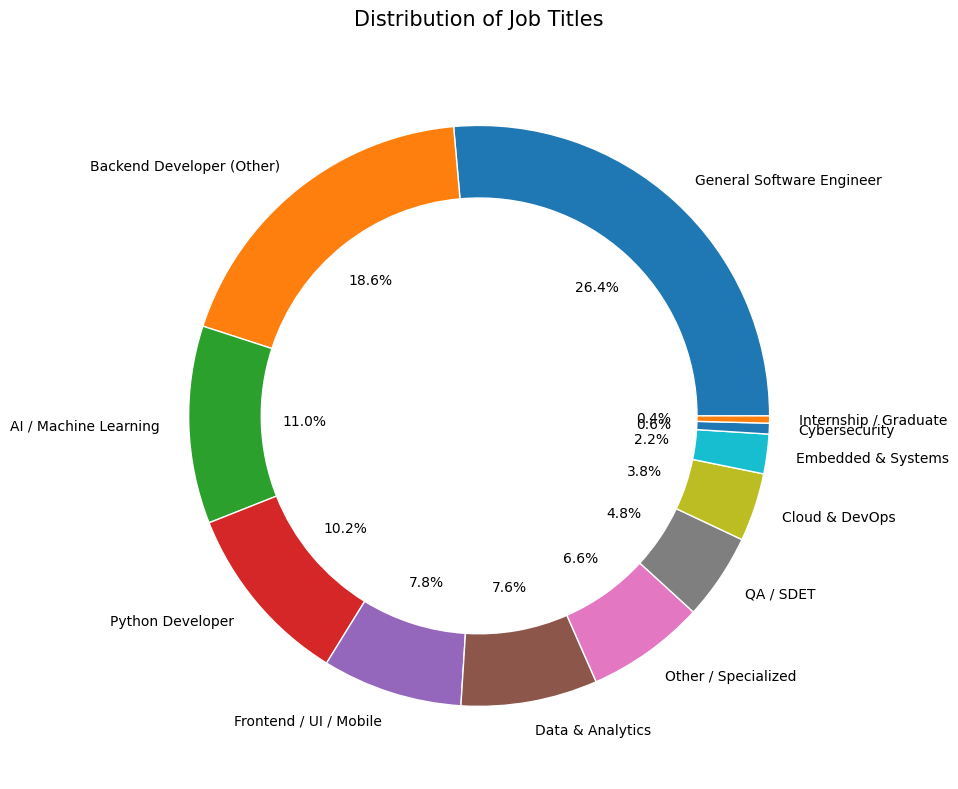

In [ ]:
plt.figure(figsize=(12,8))
pie = plt.pie(title_dist.values, labels=title_dist.index, autopct="%1.1f%%",wedgeprops={'width': 0.25, 'edgecolor': 'w'})

plt.title("Distribution of Job Titles", fontsize=15, pad=20)
plt.tight_layout()
plt.show()

This chart displays the frequency of various job titles across the job postings. It shows which roles are most commonly advertised, giving a snapshot of the current job market landscape.

<h2>Trend of Job Postings by Job Title Group and Experience Level</h2>

In [ ]:
df_tit_lvl = data.groupby(['job_group', 'seniority_level']).size()
df_tl = df_tit_lvl.unstack(fill_value=0)
df_tl['Total'] = df_tl.sum(axis=1)
df_tl = df_tl.sort_values(by='Total', ascending=False)
df_tl

seniority_level,Not specified,director,entry,internship,junior,lead,mid,senior,staff,Total
job_group,,,,,,,,,,
General Software Engineer,74,2,6,9,17,1,12,11,0,132
Backend Developer (Other),51,0,0,1,10,4,9,18,0,93
AI / Machine Learning,24,2,2,10,9,2,0,6,0,55
Python Developer,30,0,2,0,1,1,11,5,1,51
Frontend / UI / Mobile,24,0,0,0,7,1,3,4,0,39
Data & Analytics,21,1,1,1,7,1,5,1,0,38
Other / Specialized,19,1,0,2,4,1,4,2,0,33
QA / SDET,14,0,0,1,2,1,3,3,0,24
Cloud & DevOps,14,0,0,0,3,0,0,2,0,19


In [ ]:
df_tl = df_tl.drop(columns='Total')

unique_titles = np.array(df_tl.index)
unique_titles_str = unique_titles.astype(str).tolist()
unique_values = df_tl.columns.tolist()

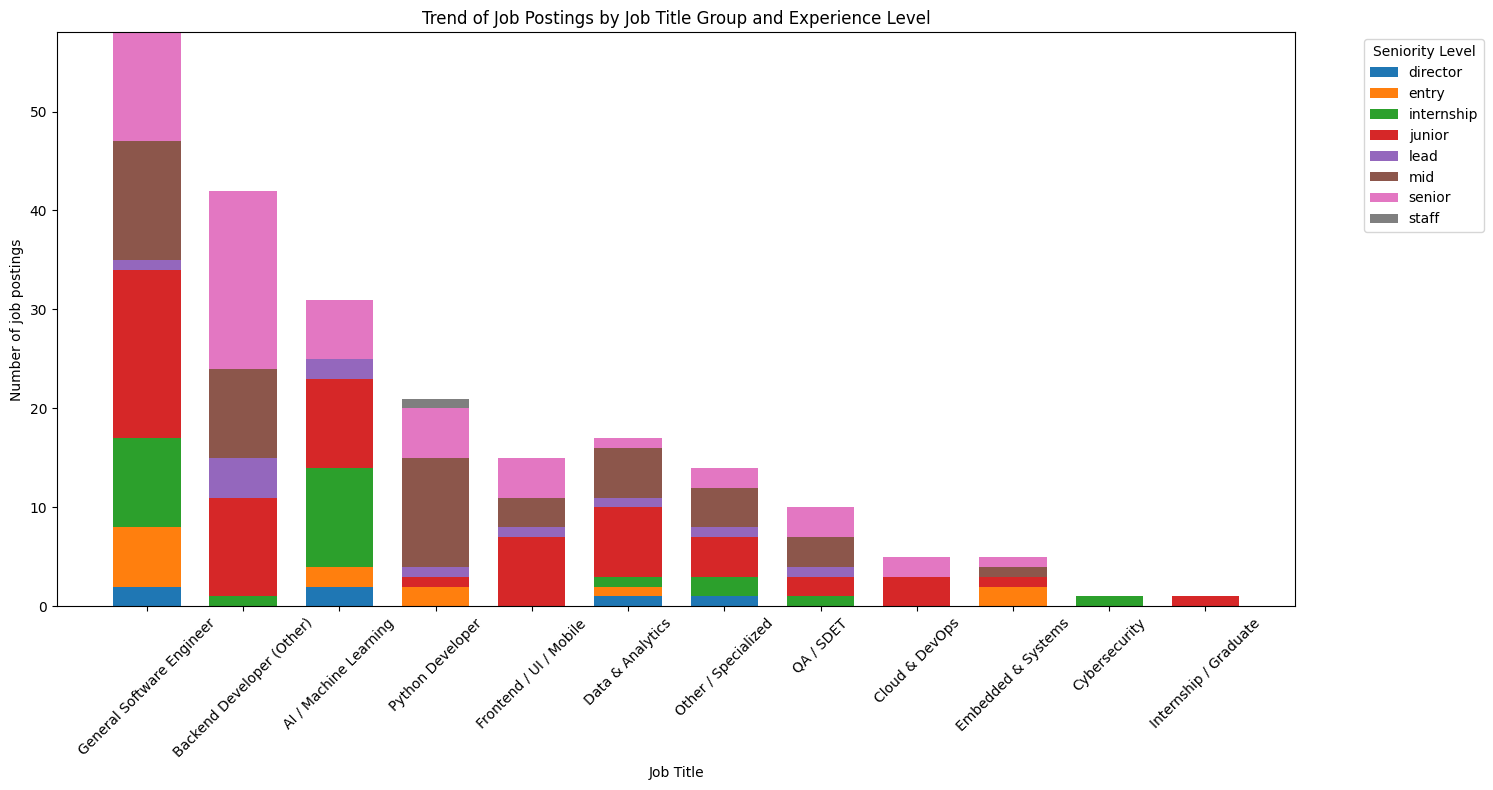

In [ ]:
fig, ax = plt.subplots(figsize=(15,8))

bottoms = np.zeros(len(unique_titles))

for level in unique_values:
  if level == "Not specified":
    continue
  column = df_tl[level]
  b = ax.bar(unique_titles_str, column, 0.7, label=level, bottom = bottoms)
  bottoms += column

ax.set_title("Trend of Job Postings by Job Title Group and Experience Level")
ax.set_xlabel("Job Title")
ax.set_ylabel("Number of job postings")
ax.legend(title="Seniority Level", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This stacked bar chart displays the number of job postings for different job title groups across various experience levels, ordered from the highest to lowest number of job postings. The x-axis represents different job title groups, and the y-axis shows the number of job postings. Each bar is divided into segments representing different experience levels, providing insights into which job titles are most prevalent and how the demand for these roles varies by experience level.

<h2>Top-4 of "Trend of Job Postings by Job Title Group and Experience Level"</h2>

In [ ]:
df_tl4 = df_tl.head(4)
unique_titles = np.array(df_tl4.index)
unique_titles_str = unique_titles.astype(str).tolist()
unique_values = df_tl4.columns.tolist()

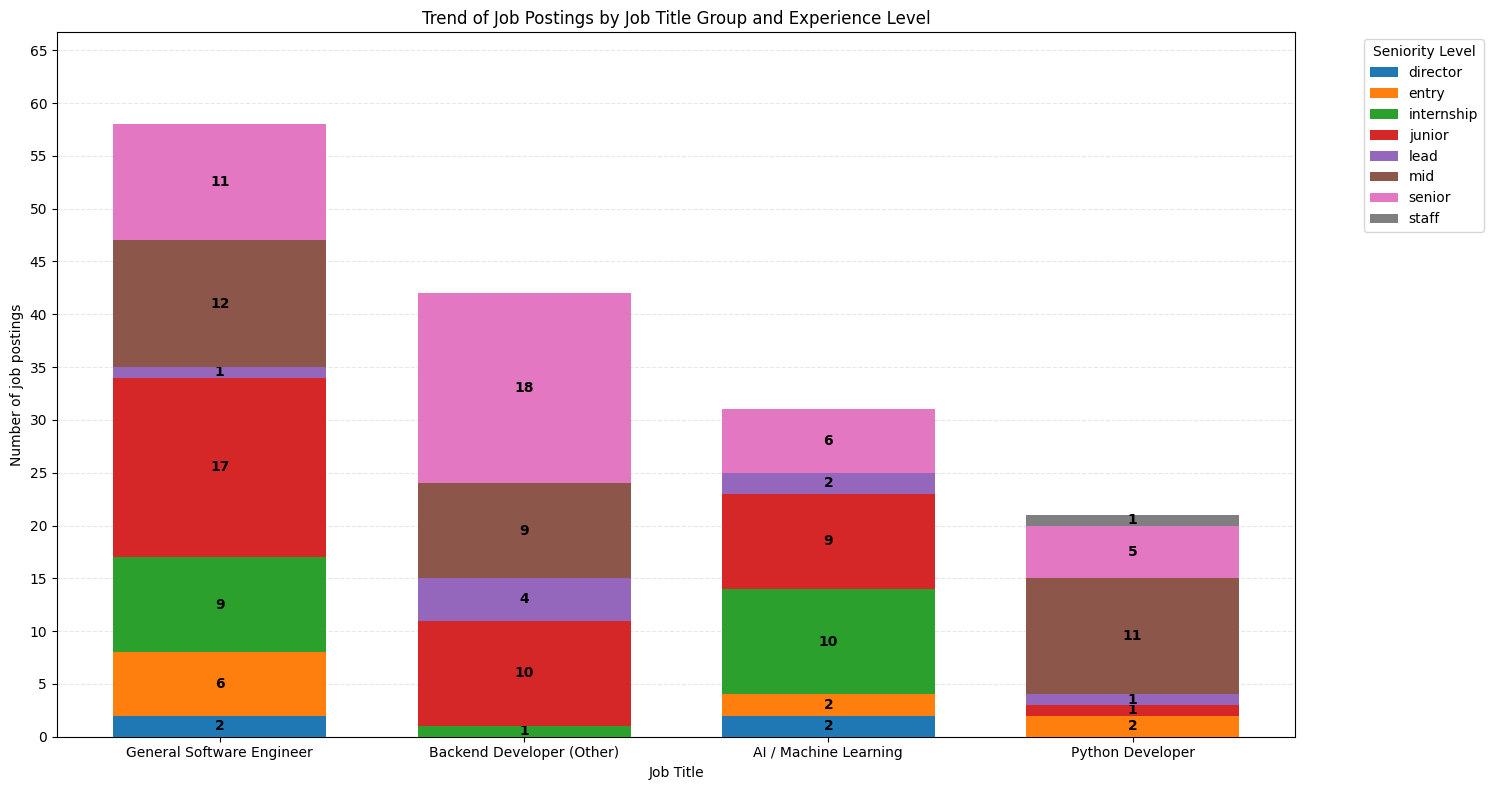

In [ ]:
fig, ax = plt.subplots(figsize=(15,8))

bottoms = np.zeros(len(unique_titles))

for level in unique_values:
  if level == "Not specified":
    continue
  column = df_tl4[level]
  b = ax.bar(unique_titles_str, column, 0.7, label=level, bottom = bottoms, zorder=3)
  bottoms += column

  if column.sum()>0:
    labels = [f'{int(v)}' if v > 0 else "" for v in column]

    ax.bar_label(b, labels=labels, label_type='center',
                  fontsize=10, fontweight='bold', color='black')

max_total = bottoms.max()
ax.set_ylim(0, max_total * 1.15)

y_step = 5
ax.set_yticks(np.arange(0, max_total + y_step * 2, y_step))

ax.set_title("Trend of Job Postings by Job Title Group and Experience Level")
ax.set_xlabel("Job Title")
ax.set_ylabel("Number of job postings")
ax.legend(title="Seniority Level", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

This plot focuses on the top four job groups and shows how the number of job postings in these groups has evolved over time, along with the experience level requirements. It provides a detailed look at the demand for major job categories.

<h2>Experience Level Distribution for jobs with python in skill</h2>

In [ ]:
df_py = data[data["python"]==True]
py_experience_dist = df_py["seniority_level"].value_counts()

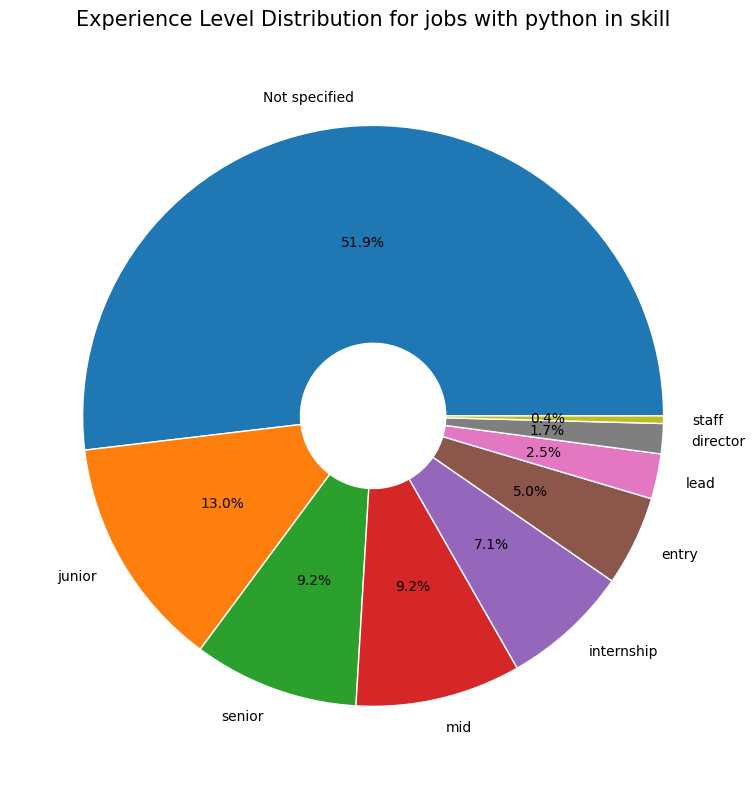

In [ ]:
plt.figure(figsize=(12,8))
pie = plt.pie(py_experience_dist.values, labels=py_experience_dist.index, autopct="%1.1f%%",
              wedgeprops={'width': 0.75, 'edgecolor': 'w'})

plt.title("Experience Level Distribution for jobs with python in skill", fontsize=15, pad=20)
plt.tight_layout()
plt.show()

This plot shows the experience level requirements specifically for the jobs that require Python knowledge. It provides insights into what level of experience is most commonly sought for roles in this specialized field.

# Data quality notes

- Dataset: 500 job postings from LinkedIn search results for Warsaw, collected on 28.03.2026; search query: Software Engineer.
- Skill flags are keyword matches on the job description. Some keywords were matched as substrings (for example `java` in "javascript", `scala` in "scalable", `rest` in "interest"), so counts for those skills are overestimated. The matching has been fixed in `extractors.py`; the dataset needs to be re-collected to refresh them.
- Applicant counts: "100+" is counted as 100, postings without a count are counted as 0, so the mean (~41) is approximate.
- Seniority is detected by keywords in the title (and the description if the title has no match), so it is approximate.

# Conclusions

1. **Most postings do not state a level.** 56% (280 of 500) have no seniority information. Explicit levels: junior 62 (12.4%), mid 48 (9.6%), senior 53 (10.6%), lead/staff/director 19 (3.8%). Junior, entry-level and internship postings together make up 100 of 500 (20%).
2. **Hybrid work leads.** Hybrid 40.4%, on-site 20%, remote 13.6%; 26% do not specify the format.
3. **Mostly full-time.** Full-time 65.6% (328), contract 2.2%, internship 2%, part-time 0.6%; 29.6% do not specify.
4. **Top employers in this sample:** Google (16 postings), Luxoft Poland (14; another 8 under "Luxoft"), PKO Bank Polski (11), Point72 (10).
5. **Competition:** about 41 applicants per posting on average.
6. **Python** appears in 239 of 500 postings (47.8%), see the data quality note about the search query.

# Implications for job seekers

- Many postings do not state a level, so it makes sense to apply to roles that look like a fit even without an explicit "junior" label.
- About one in five postings is aimed at junior, entry-level or intern candidates.
- Hybrid is the most common work format in Warsaw; fully remote roles are a minority.